<a href="https://colab.research.google.com/github/sankeawthong/Project-1-Lita-Chatbot/blob/main/Lab13_QLearning_FrozenLake_Taxi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 13 — Q-Learning on FrozenLake and Taxi

**Machine Learning · Week 13 **

| | |
|---|---|
| **Time budget** | ~2 hours (in-lab) |
| **Learning objectives** | 1. Train a tabular Q-learning agent from experience only (`reset` and `step`, no map) — 2. Read and visualise a Q-table and its greedy policy — 3. Watch a Q-table converge — 4. Compare ε strategies — 5. Contrast Q-learning with SARSA |
| **Environments** | our 4 × 4 delivery-robot **GridWorld** (Lab 12) · `FrozenLake-v1` · `Taxi` · `CliffWalking-v1` |
| **Grading** | Exercises 1–6 + AI-usage disclosure · self-checks give instant feedback |

> **The story continues.** Last week we gave value iteration the rules of the floor (`model`). The company's real robot does not come with that function — it only has `reset()` and `step()`. Today it learns the values by moving. Every number you compute matches the Week 13 lecture: start value **1.81**, greedy path optimal from **episode 13**, FrozenLake **100% / 75.1%**, Taxi **−776 → +7.85**, cliff **−47.4 vs −28.8**.
>
> Each part starts with a 🔮 **predict before you run** line. Write one sentence before you run the cell — it is not graded, but it is how you find out what you really expected.

**Textbook:** Géron (2nd ed.), Ch. 18 — Temporal Difference Learning (Eq. 18-4), Q-Learning (Eq. 18-5), Exploration Policies (pp. 632–633).

**First:** File → Save a copy in Drive, rename to `Lab13_<your_student_id>`.

---
## Setup

In [1]:
try:
    import gymnasium as gym
except ImportError:                       # Colab usually has it; install if not
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium"], check=True)
    import gymnasium as gym

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gymnasium import spaces
from gymnasium.wrappers import TimeLimit

def make_taxi():
    # Taxi is 'Taxi-v4' in Gymnasium ≥ 1.1 and 'Taxi-v3' before that — same rules
    try:
        return gym.make("Taxi-v4")
    except Exception:
        return gym.make("Taxi-v3")

print("Gymnasium", gym.__version__, "· setup complete ✔")

Gymnasium 1.4.0 · setup complete ✔


### The tools used all lab

Read these three helpers once — every part uses them.

| helper | what it does |
|---|---|
| `choose_action(Q, s, eps, rng)` | ε-greedy: with probability ε a random action, otherwise the best one — **ties broken at random** |
| `q_learning(env, episodes, alpha, gamma, eps_fn, seed)` | trains a Q-table from experience only; returns the table, the return and length of every episode |
| `evaluate(env, Q, n)` | plays `n` episodes with the **greedy** policy (no exploration) and reports mean return, success rate, mean length |

In [2]:
def greedy(Q, s, rng):
    best = np.flatnonzero(Q[s] == Q[s].max())          # all actions that tie for the best value
    return int(rng.choice(best))                         # break ties at random

def choose_action(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))             # explore
    return greedy(Q, s, rng)                             # exploit

def q_target(Q, r, s2, a2, terminated, gamma):
    # Q-learning target: reward + γ · best value of the next state (no future after a terminal step)
    return r + (0.0 if terminated else gamma * Q[s2].max())

def q_learning(env, episodes, alpha, gamma, eps_fn, seed=0, target_fn=q_target, snapshots=False, q0=0.0):
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.full((nS, nA), float(q0)); rng = np.random.default_rng(seed)
    returns, lengths, deltas, snaps = [], [], [], []
    for ep in range(episodes):
        eps = eps_fn(ep)
        s, _ = env.reset(seed=seed * 100000 + ep)
        a = choose_action(Q, s, eps, rng)
        G, n, done, biggest = 0.0, 0, False, 0.0
        while not done:
            s2, r, terminated, truncated, _ = env.step(a)
            a2 = choose_action(Q, s2, eps, rng)
            change = alpha * (target_fn(Q, r, s2, a2, terminated, gamma) - Q[s, a])
            Q[s, a] += change
            biggest = max(biggest, abs(change))
            s, a = s2, a2; G += r; n += 1; done = terminated or truncated
        returns.append(G); lengths.append(n); deltas.append(biggest)
        if snapshots: snaps.append(Q.copy())
    out = {"Q": Q, "returns": np.array(returns), "lengths": np.array(lengths), "deltas": np.array(deltas)}
    if snapshots: out["snaps"] = snaps
    return out

def evaluate(env, Q, n=1000, seed=0):
    rng = np.random.default_rng(seed); R, L, wins = [], [], 0
    for ep in range(n):
        s, _ = env.reset(seed=10**6 + ep); G, k, done = 0.0, 0, False
        while not done:
            s, r, terminated, truncated, _ = env.step(greedy(Q, s, rng)); G += r; k += 1; done = terminated or truncated
        R.append(G); L.append(k); wins += bool(terminated and r > 0)
    return {"mean_return": float(np.mean(R)), "success": wins / n, "mean_length": float(np.mean(L))}

print("helpers ready ✔")

helpers ready ✔


---
## Part 1 · Q-learning on our GridWorld — no map

The same delivery robot as Lab 12: start (0, 0), door (3, 3) = +10, puddle (1, 2) = −10, −1 per move, 50-step limit.
This time the agent never calls `model()` — it only plays episodes.

In [3]:
MOVES = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}     # up, right, down, left
NAMES = ["up", "right", "down", "left"]
ARROW = ["↑", "→", "↓", "←"]

class GridWorldEnv(gym.Env):                               # exactly the Lab 12 environment
    def __init__(self, size=4, goal=(3, 3), puddle=(1, 2), max_steps=50):
        super().__init__()
        self.size, self.goal, self.puddle, self.max_steps = size, goal, puddle, max_steps
        self.observation_space = spaces.Discrete(size * size)
        self.action_space = spaces.Discrete(4)
    def _obs(self): return self.pos[0] * self.size + self.pos[1]
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); self.pos, self.t = (0, 0), 0
        return self._obs(), {}
    def step(self, action):
        dr, dc = MOVES[int(action)]; r, c = self.pos[0] + dr, self.pos[1] + dc
        if 0 <= r < self.size and 0 <= c < self.size: self.pos = (r, c)
        self.t += 1
        if self.pos == self.goal:     reward, terminated = 10.0, True
        elif self.pos == self.puddle: reward, terminated = -10.0, True
        else:                         reward, terminated = -1.0, False
        truncated = self.t >= self.max_steps and not terminated
        return self._obs(), reward, terminated, truncated, {}

# Q* from the map (value iteration) — only to CHECK the learner, never used by it
def q_star_grid(gamma=0.9):
    def model(s, a):
        r0, c0 = divmod(s, 4); dr, dc = MOVES[a]; r, c = r0 + dr, c0 + dc
        if not (0 <= r < 4 and 0 <= c < 4): r, c = r0, c0
        s2 = r * 4 + c
        return (s2, 10.0, True) if s2 == 15 else (s2, -10.0, True) if s2 == 6 else (s2, -1.0, False)
    Q = np.zeros((16, 4))
    for _ in range(200):
        new = Q.copy()
        for s in range(16):
            if s in (6, 15): continue
            for a in range(4):
                s2, r, d = model(s, a); new[s, a] = r + (0 if d else gamma * Q[s2].max())
        Q = new
    return Q

def show_policy(Q, holes=(6,), goal=15, size=4):
    rows = []
    for r in range(size):
        rows.append(" ".join("P" if r * size + c in holes else "G" if r * size + c == goal else ARROW[int(np.argmax(Q[r * size + c]))] for c in range(size)))
    print("\n".join(rows))

Q_STAR = q_star_grid(0.9)
print("ready ✔")

ready ✔


> 🔮 **Predict before you run.** After 500 episodes with ε = 0.1, will the learned value of the start cell be close to last week's V*(start) = 1.81? Will EVERY cell be right?
>
> *My prediction:* …

In [4]:
grid = GridWorldEnv()
run = q_learning(grid, 500, alpha=0.5, gamma=0.9, eps_fn=lambda e: 0.1, seed=0, snapshots=True)
Q = run["Q"]
print("start value (max Q):", round(Q[0].max(), 4), " ·  from the map:", round(Q_STAR[0].max(), 4))
print("greedy policy:"); show_policy(Q)
print("greedy evaluation:", evaluate(grid, Q, 100))

start value (max Q): 1.8098  ·  from the map: 1.8098
greedy policy:
→ ↓ → ↓
↑ ↓ P ↓
→ → → ↓
↑ → → G
greedy evaluation: {'mean_return': 5.0, 'success': 1.0, 'mean_length': 6.0}


In [5]:
# Where is the learned table right, and where is it still wrong?
V_learned, V_map = Q.max(1).reshape(4, 4), Q_STAR.max(1).reshape(4, 4)
for V in (V_learned, V_map): V[1, 2] = V[3, 3] = 0
print("learned:\n", V_learned.round(2), "\nfrom the map:\n", V_map.round(2))
visits = np.zeros(16)
for snap_prev, snap in zip([np.zeros_like(Q)] + run["snaps"][:-1], run["snaps"]):
    visits += (np.abs(snap - snap_prev).sum(1) > 0)
print("episodes in which each cell was updated:\n", visits.reshape(4, 4).astype(int))

learned:
 [[ 1.81  3.12  4.57  6.2 ]
 [ 0.63  4.58  0.    8.  ]
 [ 4.58  6.2   8.   10.  ]
 [-1.12  8.   10.    0.  ]] 
from the map:
 [[ 1.81  3.12  4.58  6.2 ]
 [ 3.12  4.58  0.    8.  ]
 [ 4.58  6.2   8.   10.  ]
 [ 6.2   8.   10.    0.  ]]
episodes in which each cell was updated:
 [[125 123  18  18]
 [ 35 113   0  30]
 [ 19 103  94  86]
 [  5  15  24   0]]


**What to notice:** along the robot's path the values are the same as value iteration — **1.81, 3.12, 4.58, 6.2, 8, 10**. Cells it rarely visits, like (3, 0) bottom-left, are still wrong (−1.12 instead of 6.2). The greedy route from the start is still optimal: +5 in 6 steps. **A table learns only what it visits.**

---
## Part 2 · FrozenLake — dry and slippery

Reward 1 only at the goal; holes end the episode with 0. Actions here are **0 = left, 1 = down, 2 = right, 3 = up** (different from our GridWorld!).
A decaying ε starts at 1 (pure exploration) and falls to 0.05 — Géron's suggested schedule (p. 632).

> 🔮 **Predict before you run.** The random agent of Lab 12 reached the goal 1.5% (dry) and 1.2% (slippery) of the time. What success rate will the learned greedy policy reach on each lake?
>
> *My prediction:* …

In [6]:
LAKE_ARROW = ["←", "↓", "→", "↑"]
def lake_policy(Q, desc=("SFFF", "FHFH", "FFFH", "HFFG")):
    for r, row in enumerate(desc):
        print(" ".join(ch if ch in "HG" else LAKE_ARROW[int(np.argmax(Q[r * 4 + c]))] for c, ch in enumerate(row)))

dry = gym.make("FrozenLake-v1", is_slippery=False)
run_dry = q_learning(dry, 2000, alpha=0.1, gamma=0.9, eps_fn=lambda e: max(0.05, 1 - e / 1200), seed=0)
print("DRY  ·", evaluate(dry, run_dry["Q"], 2000)); lake_policy(run_dry["Q"])

slip = gym.make("FrozenLake-v1", is_slippery=True)
run_slip = q_learning(slip, 20000, alpha=0.1, gamma=0.99, eps_fn=lambda e: max(0.05, 1 - e / 12000), seed=0)   # ≈ 30–60 s
print("\nSLIPPERY ·", evaluate(slip, run_slip["Q"], 2000)); lake_policy(run_slip["Q"])

DRY  · {'mean_return': 1.0, 'success': 1.0, 'mean_length': 6.0}
→ → ↓ ←
↑ H ↓ H
→ → ↓ H
H → → G

SLIPPERY · {'mean_return': 0.751, 'success': 0.751, 'mean_length': 43.7035}
← ↑ ↑ ↑
← H → H
↑ ↓ ← H
H → ↓ G


**What to notice:** dry → **100%** in 6 steps. Slippery → **75.1%** — the best any policy can do on this map is about 74%, so this is as good as it gets. Look at the start cell of the slippery policy: it pushes **left, into the wall**. Pushing into the wall means the robot either stays or slips up/down — it can never slip right toward the hole at (1, 1).

---
## Part 3 · Watching the Q-table converge

Two views of the GridWorld run from Part 1: snapshots of the table (max Q per cell) and the **largest change** made to the table in each episode.

> 🔮 **Predict before you run.** Will the largest change per episode shrink steadily, or in jumps?
>
> *My prediction:* …

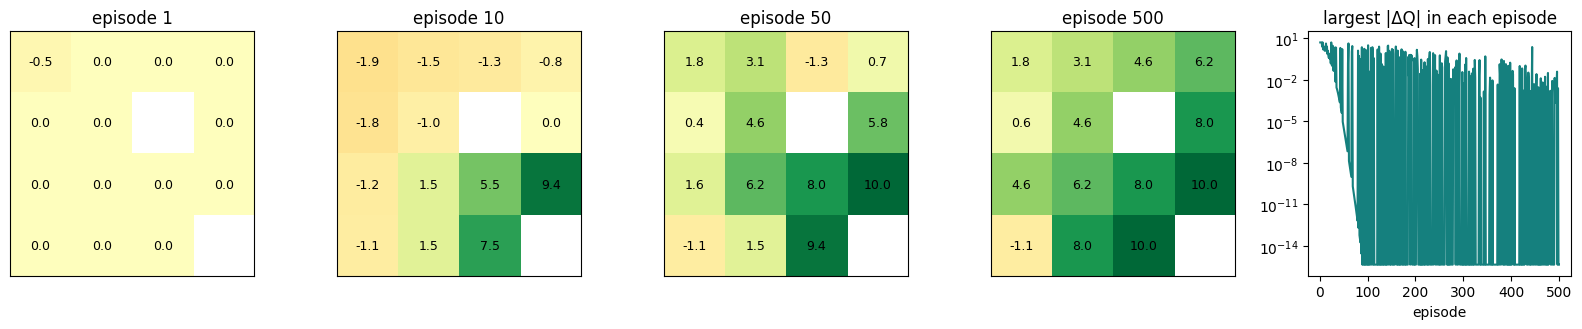

In [7]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, k in zip(axs[:4], [1, 10, 50, 500]):
    V = run["snaps"][k - 1].max(1).reshape(4, 4).copy(); V[1, 2] = V[3, 3] = np.nan
    ax.imshow(V, cmap="RdYlGn", vmin=-10, vmax=10)
    for r in range(4):
        for c in range(4):
            if not np.isnan(V[r, c]): ax.text(c, r, f"{V[r, c]:.1f}", ha="center", va="center", fontsize=9)
    ax.set_title(f"episode {k}"); ax.set_xticks([]); ax.set_yticks([])
axs[4].plot(np.arange(1, 501), run["deltas"], color="#15807E"); axs[4].set_yscale("log")
axs[4].set_title("largest |ΔQ| in each episode"); axs[4].set_xlabel("episode")
plt.tight_layout(); plt.show()

**What to notice:** values appear next to the door first and spread backwards along the path. The changes shrink, but in bursts — every time exploration tries a rarely-visited move, the table still has something to learn.

---
## Part 4 · Taxi — 500 states, 6 actions

State = taxi row × column × passenger location × destination (5 × 5 × 5 × 4 = 500). Actions: south, north, east, west, pick-up, drop-off.
Rewards: −1 per step, +20 for a correct drop-off, −10 for an illegal pick-up or drop-off.

> 🔮 **Predict before you run.** A random taxi averages about −776 per episode. After 2,000 episodes of Q-learning, what will the greedy policy average?
>
> *My prediction:* …

In [8]:
taxi = make_taxi()
print("Q-table size:", taxi.observation_space.n, "×", taxi.action_space.n, "=", taxi.observation_space.n * taxi.action_space.n)

rng = np.random.default_rng(0); rand = []
for ep in range(1000):
    s, _ = taxi.reset(seed=ep); G, done = 0.0, False
    while not done:
        s, r, term, trunc, _ = taxi.step(int(rng.integers(6))); G += r; done = term or trunc
    rand.append(G)
print("random agent: mean return", round(np.mean(rand), 1))

run_taxi = q_learning(taxi, 2000, alpha=0.5, gamma=0.95, eps_fn=lambda e: max(0.05, 1 - e / 1000), seed=0)
print("training return: first 100 episodes", round(run_taxi["returns"][:100].mean(), 1), "· last 100", round(run_taxi["returns"][-100:].mean(), 2))
print("greedy policy:", evaluate(taxi, run_taxi["Q"], 1000))

Q-table size: 500 × 6 = 3000
random agent: mean return -776.0
training return: first 100 episodes -722.5 · last 100 5.48
greedy policy: {'mean_return': 7.849, 'success': 1.0, 'mean_length': 13.151}


In [9]:
# Watch one greedy episode (text rendering)
show = gym.make(taxi.spec.id, render_mode="ansi"); s, _ = show.reset(seed=42); rng = np.random.default_rng(0)
frames, done = [show.render()], False
while not done:
    s, r, term, trunc, _ = show.step(greedy(run_taxi["Q"], s, rng)); frames.append(show.render()); done = term or trunc
print(f"{len(frames) - 1} steps, last reward {r}"); print(frames[0]); print(frames[-1])

13 steps, last reward 20
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)



---
## Part 5 · Comparing ε strategies on Taxi

Four strategies, 5 runs each, 2,000 episodes: fixed ε = 0.01, 0.1, 0.3 and a decay from 1 to 0.05. (≈ 1–2 minutes.)

> 🔮 **Predict before you run.** Which strategy reaches a positive average training return first? Which has the best FINAL greedy policy?
>
> *My prediction:* …

,strategy,episodes to mean ≥ 0,"training return, last 200",greedy return,greedy success
0,ε = 0.01,393.0,7.2,7.98,1.0
1,ε = 0.1,469.0,2.3,7.99,1.0
2,ε = 0.3,NaN,-15.0,8.00,1.0
3,decay 1 → 0.05,896.0,5.3,8.01,1.0


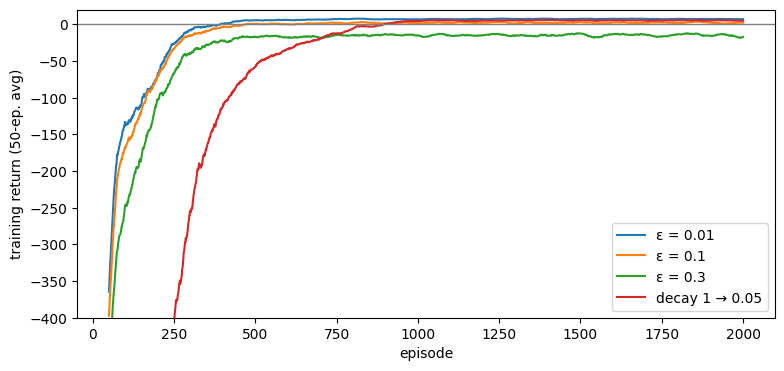

In [10]:
strategies = {"ε = 0.01": lambda e: 0.01, "ε = 0.1": lambda e: 0.1, "ε = 0.3": lambda e: 0.3,
              "decay 1 → 0.05": lambda e: max(0.05, 1 - e / 1000)}
def first_episode_at_or_above(curve, level=0, window=50):
    m = np.convolve(curve, np.ones(window) / window, mode="valid"); hit = np.flatnonzero(m >= level)
    return int(hit[0] + window) if len(hit) else None

rows, curves = [], {}
for name, fn in strategies.items():
    runs = [q_learning(make_taxi(), 2000, 0.5, 0.95, fn, seed=sd) for sd in range(5)]
    curve = np.mean([r["returns"] for r in runs], axis=0); curves[name] = curve
    greedy_eval = [evaluate(make_taxi(), r["Q"], 300) for r in runs]
    rows.append({"strategy": name, "episodes to mean ≥ 0": first_episode_at_or_above(curve),
                 "training return, last 200": round(curve[-200:].mean(), 1),
                 "greedy return": round(np.mean([g["mean_return"] for g in greedy_eval]), 2),
                 "greedy success": np.mean([g["success"] for g in greedy_eval])})
eps_table = pd.DataFrame(rows); display(eps_table)

plt.figure(figsize=(9, 4))
for name, c in curves.items(): plt.plot(np.arange(50, 2001), np.convolve(c, np.ones(50) / 50, mode="valid"), label=name)
plt.axhline(0, color="grey", lw=1); plt.ylim(-400, 20); plt.xlabel("episode"); plt.ylabel("training return (50-ep. avg)"); plt.legend(); plt.show()

**What to notice:** ε = 0.01 reaches a positive return first (**393** episodes), ε = 0.3 never does — yet **all four** greedy policies end near +8.0 with 100% success. Q starts at 0 while every real step costs −1, so untried actions look *better* than tried ones: the zero start already explores. The ε strategy changed the **cost** of learning, not the final result — here.

---
# Exercises (graded)

Fill in every `...`. Run the self-check cell after each exercise.

### Exercise 1 · The Q-learning update

Write `q_update(Q, s, a, r, s2, terminated, alpha, gamma)` that changes `Q[s, a]` **in place** using

Q(s, a) ← Q(s, a) + α · [ r + γ · max Q(s′, ·) − Q(s, a) ]

with **no future term** when `terminated` is True. Check it against the in-class activity: Q = 4, r = −1, γ = 0.9, max Q(s′, ·) = 10, α = 0.5 → **6**.

In [ ]:
def q_update(Q, s, a, r, s2, terminated, alpha, gamma):
    target = ...
    Q[s, a] += ...
    return Q[s, a]

In [ ]:
# ✅ Self-check — Exercise 1
Qt = np.zeros((2, 2)); Qt[0, 0] = 4; Qt[1] = [10, 3]
assert abs(q_update(Qt, 0, 0, -1, 1, False, 0.5, 0.9) - 6.0) < 1e-9, "Activity 1: target = −1 + 0.9 · 10 = 8, so Q = 4 + 0.5 · (8 − 4) = 6. Did you subtract the OLD Q(s, a)?"
Qt = np.zeros((2, 2)); Qt[1] = [10, 3]
assert abs(q_update(Qt, 0, 1, 10, 1, True, 0.5, 0.9) - 5.0) < 1e-9, "A terminated step has no future: target = r = 10, so Q = 0 + 0.5 · 10 = 5."
# your update inside the full training loop must reproduce Part 1 exactly
mine = q_learning(GridWorldEnv(), 500, 0.5, 0.9, lambda e: 0.1, seed=0,
                  target_fn=lambda Q, r, s2, a2, term, g: r + (0.0 if term else g * Q[s2].max()))
Qm = np.zeros((16, 4)); env_c = GridWorldEnv(); rng_c = np.random.default_rng(0)
for ep in range(500):
    s, _ = env_c.reset(seed=ep); a = choose_action(Qm, s, 0.1, rng_c); done = False
    while not done:
        s2, r, term, trunc, _ = env_c.step(a); a2 = choose_action(Qm, s2, 0.1, rng_c)
        q_update(Qm, s, a, r, s2, term, 0.5, 0.9); s, a, done = s2, a2, term or trunc
assert np.allclose(Qm, run["Q"]), "Training with your q_update should give exactly the Part 1 table."
print("Exercise 1 ✔  — 6.0 and 5.0, and the Part 1 table (start value", round(Qm[0].max(), 2), ")")

### Exercise 2 · ε-greedy with random tie-breaking

Write `my_epsilon_greedy(q_row, eps, rng)` for **one row** of a Q-table: with probability ε return a random action, otherwise one of the actions with the **largest** value, chosen at random among ties.

Why ties matter: at the start every row is all zeros. `np.argmax` would always return action 0 — the agent would keep pushing the same way.

In [ ]:
def my_epsilon_greedy(q_row, eps, rng):
    if ...:
        return ...
    best = ...                      # indices of all actions that tie for the max (hint: np.flatnonzero)
    return ...

In [ ]:
# ✅ Self-check — Exercise 2
rng_t = np.random.default_rng(1)
picks = np.bincount([my_epsilon_greedy(np.zeros(4), 0.0, rng_t) for _ in range(4000)], minlength=4) / 4000
assert np.all(np.abs(picks - 0.25) < 0.03), f"All-zero row with ε = 0: each action should be picked ≈ 25%, got {picks.round(3)}. Are you breaking ties at random?"
assert all(my_epsilon_greedy(np.array([0, 5, 1, 2.0]), 0.0, rng_t) == 1 for _ in range(200)), "With ε = 0 and a clear best action, always pick it."
best_share = np.mean([my_epsilon_greedy(np.array([0, 5, 1, 2.0]), 0.2, rng_t) == 1 for _ in range(20000)])
assert abs(best_share - 0.85) < 0.015, f"ε = 0.2 with 4 actions: the best action should be picked 1 − ε + ε/4 = 85% of the time, got {best_share:.3f}."
print(f"Exercise 2 ✔  — ties ≈ {picks.round(2)}, best action picked {best_share:.1%} at ε = 0.2")

### Exercise 3 · SARSA on the cliff

SARSA uses the action the agent **actually takes next** (`a2`) instead of the max. Complete `sarsa_target`, then run both learners on `CliffWalking-v1` (4 × 12, −1 per step, the cliff = −100 and back to start), 10 runs each.
Expected: **Q-learning −47.4, SARSA −28.8** average return over the last 100 episodes.

In [ ]:
def sarsa_target(Q, r, s2, a2, terminated, gamma):
    return ...

In [ ]:
cliff = lambda: TimeLimit(gym.make("CliffWalking-v1"), 500)
res = {}
for name, fn in [("Q-learning", q_target), ("SARSA", sarsa_target)]:
    runs = [q_learning(cliff(), 500, 0.5, 1.0, lambda e: 0.1, seed=sd, target_fn=fn) for sd in range(10)]
    res[name] = {"online return, last 100": np.mean([r["returns"][-100:].mean() for r in runs]), "first run": runs[0]}
    print(f"{name:10s}  average return while learning (last 100 episodes): {res[name]['online return, last 100']:.1f}")

def cliff_route(Q):
    env = cliff(); s, _ = env.reset(seed=0); route, rng = [s], np.random.default_rng(0)
    for _ in range(60):
        s, r, term, trunc, _ = env.step(greedy(Q, s, rng)); route.append(s)
        if term or r == -100: break
    return route
for name in res: print(name, "greedy route length:", len(cliff_route(res[name]["first run"]["Q"])) - 1, "steps")

In [ ]:
# ✅ Self-check — Exercise 3
assert abs(res["Q-learning"]["online return, last 100"] - (-47.357)) < 0.05, "Q-learning should average −47.4 (same seeds as the lecture)."
assert abs(res["SARSA"]["online return, last 100"] - (-28.848)) < 0.05, "SARSA should average −28.8. Did you use Q[s2, a2] — the action actually chosen — and no future after a terminal step?"
print("Exercise 3 ✔  — Q-learning learns the edge (13 steps) but scores −47.4; SARSA keeps away and scores −28.8")

### Exercise 4 · A decaying ε schedule

Write `linear_decay(episode, start=1.0, end=0.05, decay_episodes=1000)` = the lecture's schedule ε = max(end, start · (1 − episode / decay_episodes)): it falls in a straight line and never goes below the floor `end`. Check with the in-class activity: **ε(200) = 0.8**, **ε(2000) = 0.05**.

In [ ]:
def linear_decay(episode, start=1.0, end=0.05, decay_episodes=1000):
    return ...

In [ ]:
# ✅ Self-check — Exercise 4
assert abs(linear_decay(0) - 1.0) < 1e-9 and abs(linear_decay(2000) - 0.05) < 1e-9, "Start at 1.0 and stay at the floor 0.05 after the decay."
assert abs(linear_decay(200) - 0.8) < 1e-9, "Activity 3: episode 200 → ε = 1 − 200/1000 = 0.8."
assert abs(linear_decay(500) - 0.5) < 1e-9, "Halfway: ε = 1 − 0.5 = 0.5."
assert abs(linear_decay(990) - 0.05) < 1e-9, "1 − 0.99 = 0.01 is below the floor, so ε = 0.05."
assert all(linear_decay(e) >= linear_decay(e + 1) for e in range(1500)), "ε should never increase."
print("Exercise 4 ✔  — ε(0) = 1.0, ε(200) = 0.8, ε(500) = 0.5, ε(950+) = 0.05")

### Exercise 5 · When has it converged?

Using `run["snaps"]` from Part 1 (one Q-table per episode), find the **first episode after which the greedy policy is optimal and stays optimal** for the rest of the run. "Optimal" here means a greedy evaluation gives return +5 (use `evaluate(GridWorldEnv(), Q_snapshot, 1)["mean_return"]`).
Expected: **13**.

In [ ]:
def episodes_until_optimal(snaps):
    first = None
    for k, Qk in enumerate(snaps, start=1):
        ...
    return first

converged_at = episodes_until_optimal(run["snaps"])
converged_at

In [ ]:
# ✅ Self-check — Exercise 5
assert converged_at == 13, f"Expected 13, got {converged_at}. Remember to RESET 'first' whenever a later snapshot is not optimal."
print("Exercise 5 ✔  — the greedy path is optimal from episode 13 onward, while the table keeps changing for hundreds more")

### Exercise 6 · Open-ended (choose any two of a–c, plus d)

**(a) Learning rate.** Train the GridWorld with α = 0.1, 0.5 and 1.0 (500 episodes, ε = 0.1, seed 0). Plot the start value `max(Q[0])` over episodes for each (use `snapshots=True`). Which settles fastest, and which never settles?

**(b) Starting values.** With ε = 0 (no deliberate exploration), train the GridWorld for 300 episodes starting from `q0=0` and from `q0=-20`. How many episodes reach the door in each case, and why? (Also try it in the playground, tab 2.)

**(c) A bigger lake.** Train on `FrozenLake8x8-v1` (slippery, 64 states). How many episodes does it take before the greedy policy succeeds at least 50% of the time? What does that tell you about tables as the state space grows?

**(d) Write-up (required, at least 3 sentences).** If the logistics company's robot had to learn on the real floor (not in a simulator), which algorithm and ε strategy would you recommend, and why?

In [ ]:
# (a), (b) or (c) — your code here
...

✍️ **(d) Write-up:**

*(write here — at least 3 sentences)*

---
## AI-usage disclosure (required)

Did you use an AI assistant (ChatGPT, Claude, Copilot, …) for any part of this lab? If yes: which tool, for which exercise, and what did you change in what it gave you? If no, write "No AI used".

*(write here)*

---
## Submitting
1. Runtime → Restart session and run all — no errors, every self-check ✔. (Parts 2 and 5 take about 1–2 minutes each.)
2. File → Download → `.ipynb`.
3. Upload `Lab13_<your_student_id>.ipynb` to the Lab 13 assignment on **MS Teams**.